# Assignment 3: Coding Part
**Course:** Machine Learning (DDA3020)

<font color=Red>*Please enter your personal information (double-click this cell to edit)*</font>  
**Name:** 文杰  
**Student ID:** 123090612

## Overview

This is the **coding section** of Assignment 3. It includes **two main questions**:

- **Question 1:** K-Means Clustering
- **Question 2:** Gaussian Mixture Models (GMM)

Please follow the instructions in each cell. Complete the missing code in blocks marked with special comments such as:
```python
##########################
## Write your code here ##
##########################
```

Once completed, execute all cells and submit your final Jupyter notebook.

## Coding Question 1: K-Means Clustering

In this question, you will implement the **core logic of K-Means** from scratch and evaluate the results using the **Silhouette score**.

### 1.1 Data Preparation
We'll begin by generating a 2D synthetic dataset for clustering.

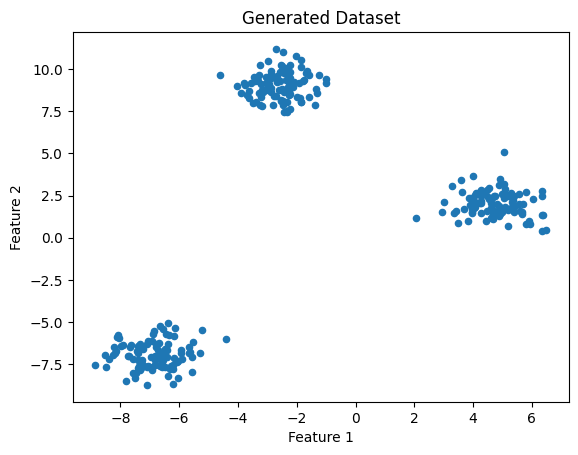

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

# Generate 2D synthetic data with 3 clusters
X, y_true = make_blobs(n_samples=300, centers=3, cluster_std=0.8, random_state=42)
plt.scatter(X[:, 0], X[:, 1], s=20)
plt.title("Generated Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

### 1.2 K-Means Core Implementation

Complete the missing sections in the `KMeans` class to implement the core algorithm:
1. **Assigning clusters** <font color=blue>(8 points)</font>  
2. **Updating cluster centers** <font color=blue>(8 points)</font>  

The method `fit()` combines these steps iteratively.

In [6]:
class KMeans:
    def __init__(self, n_clusters=3, max_iter=100):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        
    def initialize_centers(self, X):
        """Randomly select K data points as initial cluster centers"""
        np.random.seed(42)  # Reproducibility
        random_idx = np.random.choice(X.shape[0], self.n_clusters, replace=False)
        return X[random_idx]
    
    def assign_clusters(self, X, centers):
        """
        Assign each point to the nearest cluster center.

        Returns:
            labels : ndarray of shape (n_samples,)
        """
        distances = np.zeros((X.shape[0], self.n_clusters))

        ##########################
        # Compute squared Euclidean distances from each point to each center using broadcasting
        diff = X[:, np.newaxis, :] - centers
        distances = np.sum(diff ** 2, axis=2)
        # Assign each point to the nearest center
        labels = np.argmin(distances, axis=1)
        return labels
        ##########################


    def update_centers(self, X, labels):
        """
        Recalculate cluster centers as the mean of points in each cluster.

        Returns:
            new_centers : ndarray of shape (n_clusters, n_features)
        """
        new_centers = np.zeros((self.n_clusters, X.shape[1]))

        ##########################
        # Update each center as the mean of points assigned to it
        for k in range(self.n_clusters):
            points_in_cluster = X[labels == k]
            if len(points_in_cluster) > 0:  # Check to avoid empty clusters
                new_centers[k] = np.mean(points_in_cluster, axis=0)
            # Note: If cluster is empty, new_centers[k] remains zero (could reinitialize, but unlikely here)
        return new_centers
        ##########################

    
    def fit(self, X):
        """Run the full K-means algorithm."""
        self.centers = self.initialize_centers(X)
        for _ in range(self.max_iter):
            labels = self.assign_clusters(X, self.centers)
            new_centers = self.update_centers(X, labels)
            if np.allclose(self.centers, new_centers):
                break
            self.centers = new_centers
        return self

### 1.3 Visualization of K-Means Result
Let's visualize the clusters and the final learned centers.

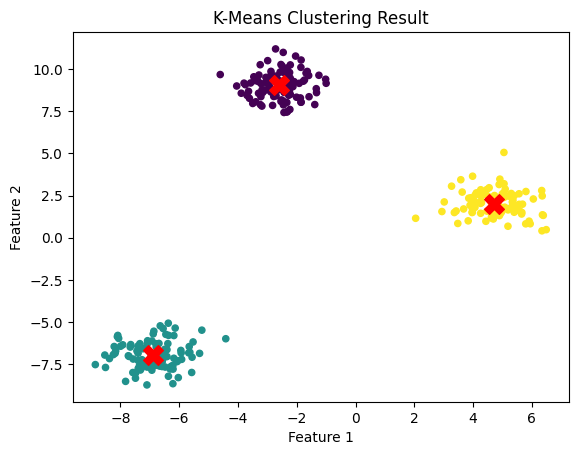

In [7]:
model = KMeans(n_clusters=3)
model.fit(X)
predicted_labels = model.assign_clusters(X, model.centers)

# Plot clustered points and centroids
plt.scatter(X[:, 0], X[:, 1], c=predicted_labels, cmap='viridis', s=20)
plt.scatter(model.centers[:, 0], model.centers[:, 1], c='red', s=200, marker='X')
plt.title("K-Means Clustering Result")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

### 1.4 Silhouette Score Evaluation

Implement a function to compute the **Silhouette Score**, which measures how well samples are clustered.

- $a(i)$: average intra-cluster distance
- $b(i)$: average nearest-cluster distance

Final score is:
$$
s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}
$$
<font color=blue>(10 points)</font>  

In [8]:
def silhouette_score(X, labels):
    """
    Compute the mean Silhouette score.

    Parameters:
        X : ndarray of shape (n_samples, n_features)
        labels : ndarray of shape (n_samples,)

    Returns:
        float: Silhouette score in [-1, 1]
    """
    n_samples = X.shape[0]
    unique_labels = np.unique(labels)
    silhouette_vals = np.zeros(n_samples)
    
    # Compute pairwise distance matrix (Euclidean distances)
    diff = X[:, np.newaxis, :] - X[np.newaxis, :, :]
    dist_matrix = np.sqrt(np.sum(diff ** 2, axis=2))
    
    for i in range(n_samples):
        cluster_id = labels[i]

        ##########################
        # Points in the same cluster
        same_cluster = (labels == cluster_id)
        n_same = np.sum(same_cluster)
        
        # Compute a(i): average distance to other points in the same cluster
        if n_same > 1:
            # Exclude self-distance (distance to the point itself)
            a_i = np.sum(dist_matrix[i, same_cluster & (np.arange(n_samples) != i)]) / (n_same - 1)
        else:
            a_i = 0  # If cluster has only one point, a(i) is undefined, set s(i) = 0 later
        
        # Compute b(i): minimum average distance to points in any other cluster
        b_i = np.inf
        for k in unique_labels:
            if k != cluster_id:
                other_cluster = (labels == k)
                if np.sum(other_cluster) > 0:
                    avg_dist_to_k = np.mean(dist_matrix[i, other_cluster])
                    if avg_dist_to_k < b_i:
                        b_i = avg_dist_to_k
        
        # Compute silhouette score s(i)
        if n_same > 1:
            s_i = (b_i - a_i) / max(a_i, b_i)
        else:
            s_i = 0  # If cluster has only one point, s(i) = 0
        
        silhouette_vals[i] = s_i
    
    return np.mean(silhouette_vals)
        ##########################



score = silhouette_score(X, predicted_labels)
print(f"Silhouette Score: {score:.3f}")

Silhouette Score: 0.878


## Coding Question 2: Gaussian Mixture Model (GMM)

In this question, you will implement a **Gaussian Mixture Model (GMM)** using the **Expectation-Maximization (EM)** algorithm.

A GMM is a probabilistic clustering model that assumes the data is generated from a mixture of $K$ Gaussian distributions:

$$
p(x) = \sum_{k=1}^K \pi_k \cdot \mathcal{N}(x \mid \mu_k, \Sigma_k)
$$

Where:
- $\pi_k$ is the mixing coefficient for the $k$-th Gaussian (with $\sum_k \pi_k = 1$)
- $\mu_k$, $\Sigma_k$ are the mean and covariance of the $k$-th Gaussian

You will:
- Implement the EM algorithm (E-step and M-step)
- Apply GMM to the same synthetic dataset as K-means
- Visualize the clustering result

### 2.1 Multivariate Gaussian Density

Before implementing GMM, we need a function to compute the multivariate Gaussian density:

$$
\mathcal{N}(x \mid \mu, \Sigma) = \frac{1}{(2\pi)^{d/2} |\Sigma|^{1/2}} \exp\left( -\frac{1}{2}(x - \mu)^T \Sigma^{-1} (x - \mu) \right)
$$

> 🛠️ **Task**: Complete the function $gaussian_pdf(x, mean, cov)$ to compute the density value at point $x$  
> The output should be a **scalar** representing $ p(x \mid \mu, \Sigma) $

<font color=blue>(8 points)</font>  

In [9]:
def gaussian_pdf(x, mean, cov):
    """
    Compute the multivariate normal density for a single sample x.

    Parameters:
        x    : (d,) array, input point
        mean : (d,) array, Gaussian mean
        cov  : (d, d) array, covariance matrix

    Returns:
        float: p(x | mean, cov)
    """
    d = x.shape[0]

    ##########################
    diff = x - mean
    inv_cov = np.linalg.inv(cov)
    quad = np.dot(diff.T, np.dot(inv_cov, diff))
    exponent = -0.5 * quad
    det_cov = np.linalg.det(cov)
    normalization = 1 / ((2 * np.pi) ** (d / 2) * np.sqrt(det_cov))
    pdf = normalization * np.exp(exponent)
    return pdf
    ##########################
    

### 2.2 GMM Class & EM Algorithm

You will now complete the core GMM algorithm by filling in the missing parts in the `e_step()` and `m_step()` methods.

#### EM Steps Recap:

- **E-step**: Compute responsibility $\gamma_k^{(n)}$ for each data point <font color=blue>(8 points)</font>  :
$$
\gamma_k^{(n)} = \frac{\pi_k \cdot \mathcal{N}(x^{(n)} \mid \mu_k, \Sigma_k)}{\sum_{j=1}^K \pi_j \cdot \mathcal{N}(x^{(n)} \mid \mu_j, \Sigma_j)}
$$

- **M-step**: Update model parameters based on current responsibilities <font color=blue>(8 points)</font>  :
$$
N_k = \sum_n \gamma_k^{(n)} \quad \quad
\mu_k = \frac{1}{N_k} \sum_n \gamma_k^{(n)} x^{(n)}
$$
$$
\Sigma_k = \frac{1}{N_k} \sum_n \gamma_k^{(n)} (x^{(n)} - \mu_k)(x^{(n)} - \mu_k)^T \quad \quad
\pi_k = \frac{N_k}{N}
$$


In [10]:
class GMM:
    def __init__(self, n_components=3, max_iter=100):
        self.K = n_components
        self.max_iter = max_iter
    
    def initialize_params(self, X):
        N, D = X.shape
        np.random.seed(42)
        idx = np.random.choice(N, self.K, replace=False)
        self.means = X[idx]
        self.covariances = np.array([np.eye(D)] * self.K)
        self.weights = np.ones(self.K) / self.K

    def e_step(self, X):
        """
        E-step: compute responsibility matrix gamma (N x K)
        return gamma
        """
        N = X.shape[0]
        gamma = np.zeros((N, self.K))

        ##########################
        # Compute likelihood for each point and component
        D = X.shape[1]
        likelihood = np.zeros((N, self.K))
        for k in range(self.K):
            mean = self.means[k]
            cov = self.covariances[k]
            inv_cov = np.linalg.inv(cov)
            det_cov = np.linalg.det(cov)
            diff = X - mean
            quad = np.sum(np.dot(diff, inv_cov) * diff, axis=1)
            likelihood[:, k] = np.exp(-0.5 * quad) / ((2 * np.pi) ** (D / 2) * np.sqrt(det_cov))
        # Compute weighted likelihood and responsibilities
        weighted_likelihood = likelihood * self.weights[np.newaxis, :]
        gamma = weighted_likelihood / np.sum(weighted_likelihood, axis=1)[:, np.newaxis]
        return gamma
        ##########################
        

    def m_step(self, X, gamma):
        """
        M-step: update weights, means, and covariances
        """
        N, D = X.shape
        Nk = np.sum(gamma, axis=0)
        self.weights = Nk / N

        ##########################
        for k in range(self.K):
            # Update mean
            self.means[k] = np.dot(gamma[:, k], X) / Nk[k]
            # Update covariance
            diff = X - self.means[k]
            self.covariances[k] = (diff.T @ (gamma[:, k][:, np.newaxis] * diff)) / Nk[k]
        ##########################

        

    def fit(self, X):
        self.initialize_params(X)
        for _ in range(self.max_iter):
            gamma = self.e_step(X)
            self.m_step(X, gamma)
        return self

    def predict(self, X):
        gamma = self.e_step(X)
        return np.argmax(gamma, axis=1)

### 2.3 Visualize GMM Clustering Result

Now that your GMM is implemented, run it on the dataset and visualize the learned clusters.

> 🛠️ **Task 3**: Run your GMM on the same dataset and display the result

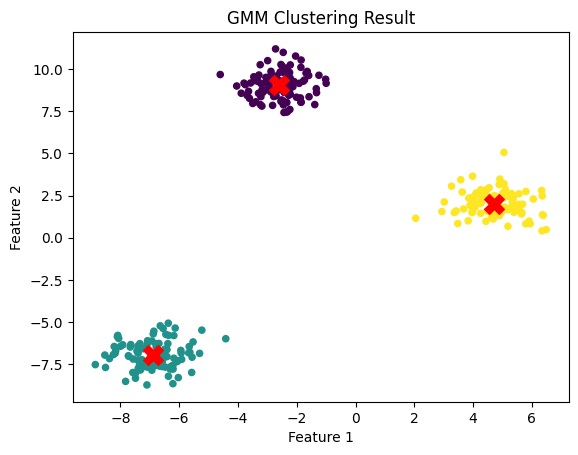

In [11]:
gmm = GMM(n_components=3)
gmm.fit(X)
gmm_labels = gmm.predict(X)

plt.scatter(X[:, 0], X[:, 1], c=gmm_labels, cmap='viridis', s=20)
plt.scatter(gmm.means[:, 0], gmm.means[:, 1], c='red', s=200, marker='X')
plt.title("GMM Clustering Result")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [12]:
print(f"KMeans Silhouette: {silhouette_score(X, predicted_labels):.3f}")
print(f"GMM    Silhouette: {silhouette_score(X, gmm_labels):.3f}")

KMeans Silhouette: 0.878
GMM    Silhouette: 0.878
